In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import joblib

In [2]:
df = pd.read_excel("DATA1_Cleaned.xlsx")

In [3]:
df.head()

,Order ID,Order Amount (INR),Delivery Time (mins),Order Date,Rating,Number of Items,Delivery Distance (km),Delivery Agent ID,Order Status,Payment Method,...,average_cost_for_two,price_range,highlights,aggregate_rating,votes,photo_count,opentable_support,delivery,state,area
0,1,1930,32,2023-04-30,4.6,9,9.200017,995,Cancelled,Debit Card,...,200,1,"['Credit Card', 'Delivery', 'Takeaway Availabl...",0.0,3,0,0,0,Kerala,38863
1,2,371,84,2023-01-06,2.7,1,8.175074,941,Cancelled,UPI,...,1000,3,"['Cash', 'Takeaway Available', 'Breakfast', 'N...",3.6,32,30,0,1,Uttar Pradesh,240928
2,3,1389,82,2024-02-18,3.9,5,13.280443,469,Delivered,Debit Card,...,1300,3,"['Cash', 'Debit Card', 'Credit Card', 'Indoor ...",4.4,174,429,0,0,Tamil Nadu,130058
3,4,329,50,2023-07-06,1.9,1,11.892893,329,In-Transit,UPI,...,400,1,"['Delivery', 'No Alcohol Available', 'Lunch', ...",3.5,33,48,0,0,Delhi,1484
4,5,400,19,2024-06-21,3.4,4,2.570476,172,Cancelled,Credit Card,...,4000,4,"['Cash', 'Dinner', 'Credit Card', 'Lunch', 'Ou...",4.1,112,134,0,0,Rajasthan,342239


In [4]:
print(df.shape)

(11867, 33)


In [5]:
df.columns = (
    df.columns
      .str.strip()
      .str.lower()
      .str.replace(" ", "_")
      .str.replace("(", "", regex=False)
      .str.replace(")", "", regex=False)
      .str.replace("/", "_", regex=False)
      .str.replace("-", "_", regex=False)
)

In [6]:
required_columns = [
    "city",
    "locality",
    "order_date"
]

In [8]:
missing_columns = []

for column in required_columns:

    if column not in df.columns:

        missing_columns.append(column)

if len(missing_columns)==0:

    print("Dataset validation successful.")

else:

    print("Missing Columns:",missing_columns)

Dataset validation successful.


In [9]:
def get_cities():

    return sorted(
        df["city"]
        .dropna()
        .unique()
        .tolist()
    )

In [10]:
cities = get_cities()

print(f"Total Cities : {len(cities)}")
print(cities[:10])        # First 10 cities

Total Cities : 76
['Agra', 'Ahmedabad', 'Ajmer', 'Alappuzha', 'Allahabad', 'Amravati', 'Amritsar', 'Aurangabad', 'Bangalore', 'Bhopal']


In [11]:
def get_localities(selected_city):

    return sorted(
        df[
            df["city"] == selected_city
        ]["locality"]
        .dropna()
        .unique()
        .tolist()
    )

In [12]:
def validate_locality(selected_city, selected_locality):

    locality_data = df[
        (df["city"] == selected_city) &
        (df["locality"] == selected_locality)
    ]

    historical_records = len(locality_data)

    return locality_data, historical_records

In [13]:
selected_city = "Chennai"

localities = get_localities(selected_city)

print(localities[:10])

['Adambakkam', 'Adyar', 'Akkarai', 'Alandur', 'Alwarpet', 'Ambassador Pallava, Egmore', 'Ambattur', 'Ambica Empire, Vadapalani', 'Ambit IT Park, Ambattur', 'Aminijikarai']


In [15]:
def get_data_quality(records):

    if records >= 100:
        return "Excellent"

    elif records >= 50:
        return "Good"

    elif records >= 30:
        return "Fair"

    else:
        return "Insufficient"

In [16]:
MIN_RECORDS = 30

def forecast_available(records):

    return records >= MIN_RECORDS

In [17]:
def validation_summary(selected_city, selected_locality):

    locality_data, historical_records = validate_locality(
        selected_city,
        selected_locality
    )

    summary = {

        "city": selected_city,

        "locality": selected_locality,

        "historical_records": historical_records,

        "data_quality": get_data_quality(
            historical_records
        ),

        "forecast_available": forecast_available(
            historical_records
        ),

        "locality_data": locality_data

    }

    return summary

In [18]:
selected_city = "Chennai"

selected_locality = "Anna Nagar"

summary = validation_summary(
    selected_city,
    selected_locality
)

summary

{'city': 'Chennai',
 'locality': 'Anna Nagar',
 'historical_records': 0,
 'data_quality': 'Insufficient',
 'forecast_available': False,
 'locality_data': Empty DataFrame
 Columns: [order_id, order_amount_inr, delivery_time_mins, order_date, rating, number_of_items, delivery_distance_km, delivery_agent_id, order_status, payment_method, tip_amount_inr, promo_code_applied, has_free_delivery, res_id, name, type, address, city, locality, latitude, longitude, cuisines, timings, average_cost_for_two, price_range, highlights, aggregate_rating, votes, photo_count, opentable_support, delivery, state, area]
 Index: []
 
 [0 rows x 33 columns]}

In [21]:
def get_validation_summary(summary):

    validation = {

        "City": summary["city"],

        "Locality": summary["locality"],

        "Historical Records": summary["historical_records"],

        "Data Quality": summary["data_quality"],

        "Forecast Status": (
            "Available"
            if summary["forecast_available"]
            else "Unavailable"
        )

    }

    return validation

In [22]:
validation = get_validation_summary(summary)

validation

{'City': 'Chennai',
 'Locality': 'Anna Nagar',
 'Historical Records': 0,
 'Data Quality': 'Insufficient',
 'Forecast Status': 'Unavailable'}

In [60]:
def create_city_dataset(selected_city):

    city_data = (
        df[df["city"] == selected_city]
        .copy()
        .sort_values("order_date")
    )

    return city_data

In [24]:
city_data = create_city_dataset(selected_city)

print(city_data.shape)

city_data.head()

(791, 33)


,order_id,order_amount_inr,delivery_time_mins,order_date,rating,number_of_items,delivery_distance_km,delivery_agent_id,order_status,payment_method,...,average_cost_for_two,price_range,highlights,aggregate_rating,votes,photo_count,opentable_support,delivery,state,area
9951,8393,543,84,2023-01-01,3.5,8,7.095766,926,In-Transit,Debit Card,...,200,1,"['Dinner', 'Takeaway Available', 'Credit Card'...",2.9,6,2,0,0,Tamil Nadu,130058
7838,6600,866,79,2023-01-01,4.1,6,14.270848,860,Delivered,Cash,...,300,1,"['Lunch', 'Cash', 'Takeaway Available', 'Credi...",0.0,2,2,0,0,Tamil Nadu,130058
7837,6600,866,79,2023-01-01,4.1,6,14.270848,860,Delivered,Cash,...,300,1,"['Lunch', 'Cash', 'Takeaway Available', 'Credi...",0.0,2,2,0,1,Tamil Nadu,130058
9280,7823,2365,56,2023-01-02,1.8,3,1.676528,401,In-Transit,Cash,...,400,1,"['Dinner', 'Delivery', 'Credit Card', 'Debit C...",3.7,83,39,0,0,Tamil Nadu,130058
9279,7823,2365,56,2023-01-02,1.8,3,1.676528,401,In-Transit,Cash,...,400,1,"['Dinner', 'Delivery', 'Credit Card', 'Debit C...",3.7,83,39,0,1,Tamil Nadu,130058


In [27]:
city_daily = (
    city_data
    .groupby("order_date")
    .size()
    .reset_index(name="orders")
)

print(city_daily.shape)

city_daily.head(10)

(342, 2)


,order_date,orders
0,2023-01-01,3
1,2023-01-02,4
2,2023-01-07,2
3,2023-01-09,4
4,2023-01-10,6
5,2023-01-11,1
6,2023-01-12,3
7,2023-01-14,5
8,2023-01-15,1
9,2023-01-17,2


In [28]:
# Filling missing dates
city_daily = (
    city_daily
    .set_index("order_date")
    .asfreq("D")
    .fillna(0)
    .reset_index()
)

city_daily["orders"] = city_daily["orders"].astype(int)

print(city_daily.shape)

city_daily.head(15)

(640, 2)


,order_date,orders
0,2023-01-01,3
1,2023-01-02,4
2,2023-01-03,0
3,2023-01-04,0
4,2023-01-05,0
5,2023-01-06,0
6,2023-01-07,2
7,2023-01-08,0
8,2023-01-09,4
9,2023-01-10,6


In [29]:
# Calendar Features

city_daily["year"] = city_daily["order_date"].dt.year

city_daily["month"] = city_daily["order_date"].dt.month

city_daily["day"] = city_daily["order_date"].dt.day

city_daily["day_of_week"] = city_daily["order_date"].dt.dayofweek

city_daily["quarter"] = city_daily["order_date"].dt.quarter

city_daily["is_weekend"] = (
    city_daily["day_of_week"] >= 5
).astype(int)

city_daily.head(10)

,order_date,orders,year,month,day,day_of_week,quarter,is_weekend
0,2023-01-01,3,2023,1,1,6,1,1
1,2023-01-02,4,2023,1,2,0,1,0
2,2023-01-03,0,2023,1,3,1,1,0
3,2023-01-04,0,2023,1,4,2,1,0
4,2023-01-05,0,2023,1,5,3,1,0
5,2023-01-06,0,2023,1,6,4,1,0
6,2023-01-07,2,2023,1,7,5,1,1
7,2023-01-08,0,2023,1,8,6,1,1
8,2023-01-09,4,2023,1,9,0,1,0
9,2023-01-10,6,2023,1,10,1,1,0


In [30]:
# Feature Engineering Function

def create_features(data):

    data = data.copy()

    # Lag Features
    data["lag_1"] = data["orders"].shift(1)
    data["lag_7"] = data["orders"].shift(7)
    data["lag_30"] = data["orders"].shift(30)

    # Rolling Features
    data["rolling_mean_7"] = (
        data["orders"]
        .rolling(window=7)
        .mean()
    )

    data["rolling_std_7"] = (
        data["orders"]
        .rolling(window=7)
        .std()
    )

    # Removing rows created due to lagging
    data = data.dropna().reset_index(drop=True)

    return data

In [31]:
city_daily = create_features(city_daily)

print(city_daily.shape)

city_daily.head(10)

(610, 13)


,order_date,orders,year,month,day,day_of_week,quarter,is_weekend,lag_1,lag_7,lag_30,rolling_mean_7,rolling_std_7
0,2023-01-31,0,2023,1,31,1,1,0,2.0,3.0,3.0,1.857143,2.035401
1,2023-02-01,0,2023,2,1,2,1,0,0.0,5.0,4.0,1.142857,1.573592
2,2023-02-02,0,2023,2,2,3,1,0,0.0,0.0,0.0,1.142857,1.573592
3,2023-02-03,0,2023,2,3,4,1,0,0.0,0.0,0.0,1.142857,1.573592
4,2023-02-04,0,2023,2,4,5,1,1,0.0,2.0,0.0,0.857143,1.573592
5,2023-02-05,4,2023,2,5,6,1,1,0.0,4.0,0.0,0.857143,1.573592
6,2023-02-06,2,2023,2,6,0,1,0,4.0,2.0,2.0,0.857143,1.573592
7,2023-02-07,2,2023,2,7,1,1,0,2.0,0.0,0.0,1.142857,1.573592
8,2023-02-08,0,2023,2,8,2,1,0,2.0,0.0,4.0,1.142857,1.573592
9,2023-02-09,0,2023,2,9,3,1,0,0.0,0.0,6.0,1.142857,1.573592


## Modeling

In [32]:
FEATURE_COLUMNS = [
    "year",
    "month",
    "day",
    "day_of_week",
    "quarter",
    "is_weekend",
    "lag_1",
    "lag_7",
    "lag_30",
    "rolling_mean_7",
    "rolling_std_7"
]

TARGET_COLUMN = "orders"

X = city_daily[FEATURE_COLUMNS]

y = city_daily[TARGET_COLUMN]

print("Feature Shape :", X.shape)
print("Target Shape  :", y.shape)

Feature Shape : (610, 11)
Target Shape  : (610,)


In [33]:
split_index = int(len(city_daily) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Samples :", len(X_train))
print("Testing Samples  :", len(X_test))

Training Samples : 488
Testing Samples  : 122


In [34]:
# Loading Model

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [66]:
# Saving trained model
joblib.dump(model, "forecast_model.pkl")

print("Model saved successfully.")

Model saved successfully.


In [35]:
# Model prediction
y_pred = model.predict(X_test)

In [36]:
# Evaluating Model

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("Linear Regression Performance")
print("-" * 35)

print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.3f}")

Linear Regression Performance
-----------------------------------
MAE  : 1.075
RMSE : 1.376
R²   : 0.066


# Model Evaluation
Linear Regression provides a simple and interpretable baseline model for forecasting daily demand. Although the R² value is modest due to high day-to-day variability, the model captures overall demand trends sufficiently for operational planning.

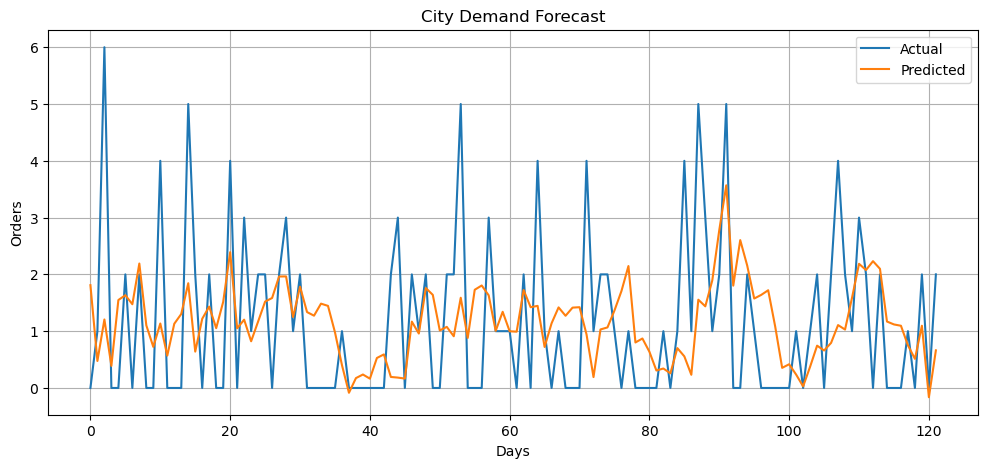

In [37]:
plt.figure(figsize=(12,5))

plt.plot(
    y_test.values,
    label="Actual"
)

plt.plot(
    y_pred,
    label="Predicted"
)

plt.title("City Demand Forecast")

plt.xlabel("Days")

plt.ylabel("Orders")

plt.legend()

plt.grid(True)

plt.show()

# Forecasting

In [38]:
# Historical Locality Contribution

locality_orders = (
    city_data
    .groupby("locality")
    .size()
    .reset_index(name="orders")
)

locality_orders["percentage"] = (
    locality_orders["orders"] /
    locality_orders["orders"].sum()
) * 100

locality_orders = locality_orders.sort_values(
    "orders",
    ascending=False
)

locality_orders.head(10)

,locality,orders,percentage
93,T. Nagar,49,6.194690
10,Anna Nagar East,42,5.309735
11,Anna Nagar West,37,4.677623
4,Alwarpet,33,4.171934
65,Nungambakkam,29,3.666245
118,Velachery,29,3.666245
1,Adyar,27,3.413401
14,Besant Nagar,21,2.654867
111,Thuraipakkam,18,2.275601
74,"Phoenix Market City, Velachery",18,2.275601


In [39]:
# Allocating Forecast to Localities

def allocate_forecast(city_forecast, locality_orders):

    allocation = locality_orders.copy()

    allocation["forecast_orders"] = (
        allocation["percentage"] / 100
    ) * city_forecast

    allocation["forecast_orders"] = (
        allocation["forecast_orders"]
        .round()
        .astype(int)
    )

    return allocation

In [40]:
allocation = allocate_forecast(
    city_forecast=120,
    locality_orders=locality_orders
)

allocation.head(10)

,locality,orders,percentage,forecast_orders
93,T. Nagar,49,6.194690,7
10,Anna Nagar East,42,5.309735,6
11,Anna Nagar West,37,4.677623,6
4,Alwarpet,33,4.171934,5
65,Nungambakkam,29,3.666245,4
118,Velachery,29,3.666245,4
1,Adyar,27,3.413401,4
14,Besant Nagar,21,2.654867,3
111,Thuraipakkam,18,2.275601,3
74,"Phoenix Market City, Velachery",18,2.275601,3


In [41]:
# Base Rider Recommendation Engine

def recommend_riders(forecast_orders):

    if forecast_orders <= 5:
        return 3

    elif forecast_orders <= 10:
        return 5

    elif forecast_orders <= 20:
        return 8

    elif forecast_orders <= 30:
        return 12

    else:
        return int(np.ceil(forecast_orders / 2))

In [42]:
allocation["recommended_riders"] = allocation[
    "forecast_orders"
].apply(recommend_riders)

allocation.head(10)

,locality,orders,percentage,forecast_orders,recommended_riders
93,T. Nagar,49,6.194690,7,5
10,Anna Nagar East,42,5.309735,6,5
11,Anna Nagar West,37,4.677623,6,5
4,Alwarpet,33,4.171934,5,3
65,Nungambakkam,29,3.666245,4,3
118,Velachery,29,3.666245,4,3
1,Adyar,27,3.413401,4,3
14,Besant Nagar,21,2.654867,3,3
111,Thuraipakkam,18,2.275601,3,3
74,"Phoenix Market City, Velachery",18,2.275601,3,3


In [43]:
# Priority Classification

def classify_priority(forecast_orders):

    if forecast_orders <= 3:
        return "🟢 Low"

    elif forecast_orders <= 6:
        return "🟡 Medium"

    elif forecast_orders <= 10:
        return "🟠 High"

    else:
        return "🔴 Critical"

In [44]:
allocation["priority"] = allocation[
    "forecast_orders"
].apply(classify_priority)

allocation.head(10)

,locality,orders,percentage,forecast_orders,recommended_riders,priority
93,T. Nagar,49,6.194690,7,5,🟠 High
10,Anna Nagar East,42,5.309735,6,5,🟡 Medium
11,Anna Nagar West,37,4.677623,6,5,🟡 Medium
4,Alwarpet,33,4.171934,5,3,🟡 Medium
65,Nungambakkam,29,3.666245,4,3,🟡 Medium
118,Velachery,29,3.666245,4,3,🟡 Medium
1,Adyar,27,3.413401,4,3,🟡 Medium
14,Besant Nagar,21,2.654867,3,3,🟢 Low
111,Thuraipakkam,18,2.275601,3,3,🟢 Low
74,"Phoenix Market City, Velachery",18,2.275601,3,3,🟢 Low


In [45]:
# Operational Recommendation

def operational_recommendation(priority):

    if priority == "🔴 Critical":
        return "Immediate rider deployment required."

    elif priority == "🟠 High":
        return "Deploy additional riders."

    elif priority == "🟡 Medium":
        return "Maintain normal staffing."

    else:
        return "No action required."

In [46]:
allocation["recommendation"] = allocation[
    "priority"
].apply(operational_recommendation)

allocation.head(10)

,locality,orders,percentage,forecast_orders,recommended_riders,priority,recommendation
93,T. Nagar,49,6.194690,7,5,🟠 High,Deploy additional riders.
10,Anna Nagar East,42,5.309735,6,5,🟡 Medium,Maintain normal staffing.
11,Anna Nagar West,37,4.677623,6,5,🟡 Medium,Maintain normal staffing.
4,Alwarpet,33,4.171934,5,3,🟡 Medium,Maintain normal staffing.
65,Nungambakkam,29,3.666245,4,3,🟡 Medium,Maintain normal staffing.
118,Velachery,29,3.666245,4,3,🟡 Medium,Maintain normal staffing.
1,Adyar,27,3.413401,4,3,🟡 Medium,Maintain normal staffing.
14,Besant Nagar,21,2.654867,3,3,🟢 Low,No action required.
111,Thuraipakkam,18,2.275601,3,3,🟢 Low,No action required.
74,"Phoenix Market City, Velachery",18,2.275601,3,3,🟢 Low,No action required.


In [47]:
top_priorities = (
    allocation
    .sort_values(
        by=["forecast_orders", "percentage"],
        ascending=False
    )
    .head(10)
)

top_priorities

,locality,orders,percentage,forecast_orders,recommended_riders,priority,recommendation
93,T. Nagar,49,6.194690,7,5,🟠 High,Deploy additional riders.
10,Anna Nagar East,42,5.309735,6,5,🟡 Medium,Maintain normal staffing.
11,Anna Nagar West,37,4.677623,6,5,🟡 Medium,Maintain normal staffing.
4,Alwarpet,33,4.171934,5,3,🟡 Medium,Maintain normal staffing.
65,Nungambakkam,29,3.666245,4,3,🟡 Medium,Maintain normal staffing.
118,Velachery,29,3.666245,4,3,🟡 Medium,Maintain normal staffing.
1,Adyar,27,3.413401,4,3,🟡 Medium,Maintain normal staffing.
14,Besant Nagar,21,2.654867,3,3,🟢 Low,No action required.
111,Thuraipakkam,18,2.275601,3,3,🟢 Low,No action required.
74,"Phoenix Market City, Velachery",18,2.275601,3,3,🟢 Low,No action required.


In [48]:
# Creating Tomorrow's Features

def create_tomorrow_features(city_daily):

    last_row = city_daily.iloc[-1]

    tomorrow = last_row["order_date"] + pd.Timedelta(days=1)

    features = {

        "year": tomorrow.year,
        "month": tomorrow.month,
        "day": tomorrow.day,
        "day_of_week": tomorrow.dayofweek,
        "quarter": ((tomorrow.month - 1)//3)+1,
        "is_weekend": int(tomorrow.dayofweek >= 5),

        "lag_1": last_row["orders"],
        "lag_7": city_daily.iloc[-7]["orders"],
        "lag_30": city_daily.iloc[-30]["orders"],

        "rolling_mean_7": city_daily["orders"].tail(7).mean(),

        "rolling_std_7": city_daily["orders"].tail(7).std()

    }

    return pd.DataFrame([features])

In [49]:
tomorrow_features = create_tomorrow_features(city_daily)

tomorrow_features

,year,month,day,day_of_week,quarter,is_weekend,lag_1,lag_7,lag_30,rolling_mean_7,rolling_std_7
0,2024,10,2,2,4,0,2,0,0,0.714286,0.95119


In [50]:
tomorrow_prediction = model.predict(
    tomorrow_features
)[0]

forecast_orders = max(1, round(tomorrow_prediction))

print("Tomorrow Forecast :", forecast_orders)

Tomorrow Forecast : 1


In [51]:
city_daily.tail(10)

,order_date,orders,year,month,day,day_of_week,quarter,is_weekend,lag_1,lag_7,lag_30,rolling_mean_7,rolling_std_7
600,2024-09-22,0,2024,9,22,6,3,1,2.0,0.0,1.0,2.000000,1.290994
601,2024-09-23,2,2024,9,23,0,3,0,0.0,2.0,0.0,2.000000,1.290994
602,2024-09-24,0,2024,9,24,1,3,0,2.0,4.0,1.0,1.428571,1.133893
603,2024-09-25,0,2024,9,25,2,3,0,0.0,2.0,4.0,1.142857,1.214986
604,2024-09-26,0,2024,9,26,3,3,0,0.0,1.0,1.0,1.000000,1.290994
605,2024-09-27,1,2024,9,27,4,3,0,0.0,3.0,5.0,0.714286,0.951190
606,2024-09-28,0,2024,9,28,5,3,1,1.0,2.0,3.0,0.428571,0.786796
607,2024-09-29,2,2024,9,29,6,3,1,0.0,0.0,1.0,0.714286,0.951190
608,2024-09-30,0,2024,9,30,0,3,0,2.0,2.0,2.0,0.428571,0.786796
609,2024-10-01,2,2024,10,1,1,4,0,0.0,0.0,5.0,0.714286,0.951190


In [52]:
# Forecast Summary

def forecast_summary(city_daily, forecast_orders):

    historical_average = city_daily["orders"].mean()

    rolling_average = city_daily["orders"].tail(7).mean()

    rolling_std = city_daily["orders"].tail(7).std()

    if rolling_std < 0.75:
        confidence = "High"

    elif rolling_std < 1.50:
        confidence = "Medium"

    else:
        confidence = "Low"

    return {
        "Forecast Orders": forecast_orders,
        "Historical Average": round(historical_average, 2),
        "7-Day Average": round(rolling_average, 2),
        "Confidence": confidence
    }

In [53]:
forecast_orders = max(0, round(tomorrow_prediction))

summary = forecast_summary(
    city_daily,
    forecast_orders
)

summary

{'Forecast Orders': 1,
 'Historical Average': 1.22,
 '7-Day Average': 0.71,
 'Confidence': 'Medium'}

In [54]:
# Business Rules

# Minimum forecast required for locality-level planning
LOW_DEMAND_THRESHOLD = 20

# Final Decision Support Engine

def run_decision_support(
    city_name,
    locality_name,
    forecast_orders,
    locality_orders,
    city_daily
):

    # Forecast Summary

    summary = forecast_summary(
        city_daily,
        forecast_orders
    )

    # Low Demand Scenario

    if forecast_orders < LOW_DEMAND_THRESHOLD:

        return {

            "forecast_orders": summary["Forecast Orders"],

            "historical_average": summary["Historical Average"],

            "moving_average": summary["7-Day Average"],

            "confidence": summary["Confidence"],

            "demand_status": "Low",

            "selected_locality": {

                "name": locality_name,

                "forecast_orders": 0,

                "recommended_riders": 0,

                "priority": "N/A",

                "recommendation":
                "Demand too low for locality-level planning."

            },

            "top_priorities": None,

            "allocation": None

        }

    # Moderate / High Demand Scenario
    
    allocation = allocate_forecast(
        forecast_orders,
        locality_orders
    )

    # Rider Recommendation
    allocation["recommended_riders"] = (
        allocation["forecast_orders"]
        .apply(recommend_riders)
    )

    # Priority Classification
    allocation["priority"] = (
        allocation["forecast_orders"]
        .apply(classify_priority)
    )

    # Operational Recommendation
    allocation["recommendation"] = (
        allocation["priority"]
        .apply(operational_recommendation)
    )

    locality_info = allocation[
        allocation["locality"] == locality_name
    ].iloc[0]

    top_priorities = (
        allocation
        .sort_values(
            by=["forecast_orders", "percentage"],
            ascending=False
        )
        .head(10)
    )

    # Final Output

    return {

        "forecast_orders":
            summary["Forecast Orders"],

        "historical_average":
            summary["Historical Average"],

        "moving_average":
            summary["7-Day Average"],

        "confidence":
            summary["Confidence"],

        "demand_status":
            "Moderate / High",

        "selected_locality": {

            "name":
                locality_info["locality"],

            "forecast_orders":
                int(locality_info["forecast_orders"]),

            "recommended_riders":
                int(locality_info["recommended_riders"]),

            "priority":
                locality_info["priority"],

            "recommendation":
                locality_info["recommendation"]

        },

        "top_priorities":
            top_priorities,

        "allocation":
            allocation

    }

In [55]:
results = run_decision_support(
    city_name=selected_city,
    locality_name=selected_locality,
    forecast_orders=forecast_orders,
    locality_orders=locality_orders,
    city_daily=city_daily
)

results

{'forecast_orders': 1,
 'historical_average': 1.22,
 'moving_average': 0.71,
 'confidence': 'Medium',
 'demand_status': 'Low',
 'selected_locality': {'name': 'Anna Nagar',
  'forecast_orders': 0,
  'recommended_riders': 0,
  'priority': 'N/A',
  'recommendation': 'Demand too low for locality-level planning.'},
 'top_priorities': None,
 'allocation': None}

In [57]:
# =====================================================
# Forecast Report
# =====================================================

def generate_forecast_report(results):

    print("=" * 60)
    print("          ZOMATO DEMAND FORECASTING & RIDER PLANNING")
    print("=" * 60)

    print(f"\nForecast Orders      : {results['forecast_orders']}")
    print(f"Historical Average   : {results['historical_average']}")
    print(f"7-Day Average        : {results['moving_average']}")
    print(f"Confidence           : {results['confidence']}")
    print(f"Demand Status        : {results['demand_status']}")

    print("\n" + "-" * 60)

    print("Selected Locality")

    print(f"Locality             : {results['selected_locality']['name']}")
    print(f"Forecast Orders      : {results['selected_locality']['forecast_orders']}")
    print(f"Recommended Riders   : {results['selected_locality']['recommended_riders']}")
    print(f"Priority             : {results['selected_locality']['priority']}")

    print("\nRecommendation")

    print(results["selected_locality"]["recommendation"])

    print("=" * 60)

In [58]:
generate_forecast_report(results)

          ZOMATO DEMAND FORECASTING & RIDER PLANNING

Forecast Orders      : 1
Historical Average   : 1.22
7-Day Average        : 0.71
Confidence           : Medium
Demand Status        : Low

------------------------------------------------------------
Selected Locality
Locality             : Anna Nagar
Forecast Orders      : 0
Recommended Riders   : 0
Priority             : N/A

Recommendation
Demand too low for locality-level planning.


# Backend Testing

Validate the complete forecasting and decision support
pipeline using a sample city and locality.

In [65]:
selected_city = "Chennai"
selected_locality = "Adyar"

city_data = create_city_dataset(
    selected_city
)

forecast_orders = max(1, round(tomorrow_prediction))

results = run_decision_support(
    city_name=selected_city,
    locality_name=selected_locality,
    forecast_orders=forecast_orders,
    locality_orders=locality_orders,
    city_daily=city_daily
)

generate_forecast_report(results)

          ZOMATO DEMAND FORECASTING & RIDER PLANNING

Forecast Orders      : 1
Historical Average   : 1.22
7-Day Average        : 0.71
Confidence           : Medium
Demand Status        : Low

------------------------------------------------------------
Selected Locality
Locality             : Adyar
Forecast Orders      : 0
Recommended Riders   : 0
Priority             : N/A

Recommendation
Demand too low for locality-level planning.
